# Notebook 4: Calibrated Concept Adapter

**Course project: Foundations of LLMs (AI60213)** · Base paper: *Soft Thinking* (Zhang et al., NeurIPS 2025)

This notebook combines our two contributions:

* the **calibrated Cold Stop** (Notebook 3), which fixes the stopping rule for a small model;
* a **calibrated concept adapter**: the concept adapter of Notebook 2, retrained **on-policy** and with a **depth-weighted** objective, so that its gap reduction carries through to the final layers.

It is compared with the paper's method (Notebook 1) and with the calibrated Cold Stop alone (Notebook 3) on the same 250 GSM8K test questions.

**Contents**

0. Briefing
1. Setup, including the outputs of Notebooks 1–3
2. Shared machinery (identical to Notebooks 1–3)
3. The calibrated adapter: what changes, and the loss
4. On-policy training traces
5. Training
6. Evaluation on the test questions
7. Comparison: paper vs calibrated Cold Stop vs calibrated Cold Stop + calibrated adapter
8. Conclusion

---
# Part 0: Briefing

## 0.1 What Notebook 2's adapter left open

The Notebook 2 adapter reduced the superposition gap significantly, but:

1. **The gain faded toward the output.** The gap fell most in the middle layers, much less at the final layer. Yet the final layer is what decides the next concept token.
2. **It was trained off-policy.** It learned on prefixes generated *without* an adapter, but at inference every earlier mixed step had already been adapted.

## 0.2 The calibrated adapter

| | Notebook 2 adapter | Calibrated adapter (this notebook) |
|---|---|---|
| Architecture | rank-64 residual MLP + norm cap, about 0.26M parameters | same |
| Initialisation | zero, i.e. the paper's method | **Notebook 2's trained adapter** (warm start) |
| Training prefixes | vanilla Soft Thinking traces | **on-policy:** traces generated **with Notebook 2's adapter and the calibrated Cold Stop**, reconstructed exactly as they were fed |
| Layer weights in the loss | uniform over layers $0..L$ | **depth-weighted:** $w_0 = 1$ (the trust-region term, unchanged), $w_\ell = 2\ell/L$ for $\ell \ge 1$, normalised |
| Cold Stop at inference | paper's setting | **calibrated** (Notebook 3) |
| Optimiser and schedule | AdamW, lr $10^{-3}$, cosine, 3 epochs, gradient clip 1.0 | same |

The depth weights average about 1 over layers $1..L$, so the overall scale of the loss is unchanged. They shift emphasis from the early layers (weight near 0) to the late layers (weight up to 2).

$$\mathcal L = \sum_{\ell=0}^{L} \tilde w_\ell\, \frac{\big\|h_\ell(\mathbf e'_t) - \sum_k c_k\, h_\ell(\mathbf e(k))\big\|^2}{\big\|\sum_k c_k\, h_\ell(\mathbf e(k))\big\|^2}, \qquad \tilde w_\ell = \frac{w_\ell}{\sum_j w_j}$$

## 0.3 Comparisons

| Comparison | Isolates |
|---|---|
| calibrated Cold Stop + calibrated adapter **vs** calibrated Cold Stop (Notebook 3) | the effect of the adapter, under the same stopping rule |
| calibrated Cold Stop + calibrated adapter **vs** paper (Notebook 1) | the combined effect of both contributions |

## 0.4 Runtime (one T4)

| Step | QUICK | FULL |
|---|---|---|
| On-policy traces on training questions | ~10 min (32) | ~1.5–2 h (400) |
| Training (3 epochs) | ~1 min | ~20 min |
| On-policy check | ~5 min | ~5 min |
| Test evaluation + diagnosis | ~6 min | ~65–85 min |
| **Total** | **~25 min** | **~3–3.5 h** |

**Inputs on Kaggle:** *Add Input → Notebooks (Your Work)* → Notebooks **1, 2 and 3**, all finished FULL runs.

---
# Part 1: Setup

In [1]:
#!pip install -q -U "transformers>=4.51" accelerate datasets

In [2]:
# Optional: a Hugging Face token avoids download rate limits (Kaggle: Add-ons -> Secrets -> HF_TOKEN).
# from kaggle_secrets import UserSecretsClient; import os
# os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")

In [3]:
import os, re, glob, json, math, time, random, pickle
from dataclasses import dataclass, asdict

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import transformers
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset
import copy
from dataclasses import replace

RUN_MODE = "FULL"      # "QUICK": short smoke test | "FULL": the reported numbers
SEED = 0

@dataclass
class Config:
    n_test: int = 250               # first n GSM8K test questions
    batch_size: int = 16            # questions decoded in parallel
    # Soft Thinking settings (identical in both notebooks)
    max_think_tokens: int = 2048
    max_answer_tokens: int = 512
    temperature: float = 0.6
    top_k: int = 15
    top_p: float = 0.95
    min_p: float = 0.001
    cold_stop: bool = True
    cold_stop_tau: float = 0.01
    cold_stop_len: int = 128
    # Diagnosis
    max_probe_steps: int = 64       # mixed steps probed per trace (memory cap)
    # Calibrated adapter (architecture and optimisation identical to Notebook 2)
    n_train: int = 400
    adapter_rank: int = 64
    adapter_lr: float = 1e-3
    adapter_epochs: int = 3
    val_frac: float = 0.1
    grad_clip: float = 1.0
    n_policy_check: int = 16

CFG = Config() if RUN_MODE == "FULL" else Config(n_test=16, n_train=32, adapter_epochs=1)

OUT_DIR = ("/kaggle/working" if os.path.isdir("/kaggle/working") else ".") + f"/calibrated_adapter_{RUN_MODE.lower()}"
os.makedirs(OUT_DIR, exist_ok=True)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cuda":
    # A T4 (compute capability 7.5) has no native bfloat16, so float16 is used there.
    DTYPE = torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    print("GPU:", torch.cuda.get_device_name(0))
else:
    DTYPE = torch.float32
    print("No GPU found: FULL mode is not practical on CPU.")
print(f"RUN_MODE={RUN_MODE} | dtype={DTYPE} | outputs -> {OUT_DIR}")
print("torch", torch.__version__, "| transformers", transformers.__version__)
CFG

GPU: Tesla T4
RUN_MODE=FULL | dtype=torch.float16 | outputs -> /kaggle/working/calibrated_adapter_full
torch 2.11.0+cu130 | transformers 5.20.2


Config(n_test=250, batch_size=16, max_think_tokens=2048, max_answer_tokens=512, temperature=0.6, top_k=15, top_p=0.95, min_p=0.001, cold_stop=True, cold_stop_tau=0.01, cold_stop_len=128, max_probe_steps=64, n_train=400, adapter_rank=64, adapter_lr=0.001, adapter_epochs=3, val_frac=0.1, grad_clip=1.0, n_policy_check=16)

## 1.1 Inputs from Notebooks 1–3

In [4]:
def find_output(folder):
    """Locate another notebook's output folder (attached on Kaggle via Add Input, or in the working dir)."""
    for mode in ("full", "quick"):
        for root in ("/kaggle/input", "."):
            hits = sorted(glob.glob(f"{root}/**/{folder}_{mode}/config.json", recursive=True))
            if hits:
                return os.path.dirname(hits[0])
    return None

NB1_DIR, NB2_DIR, NB3_DIR = (find_output(f) for f in ("soft_thinking_paper", "concept_adapter", "calibrated_cold_stop"))
for n, d in (("1", NB1_DIR), ("2", NB2_DIR), ("3", NB3_DIR)):
    assert d, f"Notebook {n}'s output not found: Add Input -> Notebooks (Your Work) -> Notebook {n} (finished run)."

def read_pkl(folder, name):
    with open(f"{folder}/{name}.pkl", "rb") as f:
        return pickle.load(f)

paper_test = read_pkl(NB1_DIR, "soft_test")[:CFG.n_test]
_ids = {r["id"] for r in paper_test}
diag_paper = read_pkl(NB1_DIR, "diag_paper").query("id in @_ids").reset_index(drop=True)
ccs_test = [r for r in read_pkl(NB3_DIR, "ccs_test") if r["id"] in _ids]
diag_ccs = read_pkl(NB3_DIR, "diag_ccs").query("id in @_ids").reset_index(drop=True)
nb2_diag = read_pkl(NB2_DIR, "diag_adapter").query("id in @_ids").reset_index(drop=True)
CAL = json.load(open(f"{NB3_DIR}/cold_stop_calibration.json"))
CFG_CAL = replace(CFG, cold_stop_tau=CAL["tau"], cold_stop_len=CAL["len"])
test_set = [{"id": r["id"], "q": r["q"], "a": r["gold"]} for r in paper_test]
times = {"paper": json.load(open(f"{NB1_DIR}/soft_test_time.json"))["seconds"],
         "ccs": json.load(open(f"{NB3_DIR}/ccs_test_time.json"))["seconds"]}
print("Notebook 1:", NB1_DIR, "\nNotebook 2:", NB2_DIR, "\nNotebook 3:", NB3_DIR)
print(f"calibrated Cold Stop: tau = {CAL['tau']}, k = {CAL['len']} | test questions: {len(test_set)} | "
      f"calibrated-Cold-Stop results: {len(ccs_test)}")

Notebook 1: /kaggle/input/notebooks/anarvaaa/fllm-project-nb1/soft_thinking_paper_full 
Notebook 2: /kaggle/input/notebooks/anarvaaa/fllm-project-nb2/concept_adapter_full 
Notebook 3: /kaggle/input/notebooks/anarvaaa/fllm-project-nb3/calibrated_cold_stop_full
calibrated Cold Stop: tau = 0.25, k = 96 | test questions: 250 | calibrated-Cold-Stop results: 250


## 1.2 Model and training questions

In [5]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tok = AutoTokenizer.from_pretrained(MODEL_NAME)
tok.padding_side = "left"                                  # batched decoding
if tok.pad_token is None:
    tok.pad_token = tok.eos_token
_dtype_kw = "dtype" if tuple(int(x) for x in transformers.__version__.split(".")[:2]) >= (4, 56) else "torch_dtype"
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **{_dtype_kw: DTYPE}).to(DEVICE).eval()
model.requires_grad_(False)                                # the LLM is always frozen

E = model.get_input_embeddings().weight                    # (vocab, d): input embedding matrix
D_MODEL = E.shape[1]
N_LAYERS = model.config.num_hidden_layers
END_THINK_ID = tok.convert_tokens_to_ids("</think>")
assert tok.decode([END_THINK_ID]) == "</think>", "model has no </think> token: use a reasoning model"
EOS_IDS = {i for i in {tok.eos_token_id, tok.convert_tokens_to_ids("<|im_end|>")} if i is not None}
EOS_ID = min(EOS_IDS)
FORCE_IDS = tok("</think>\n\n", add_special_tokens=False).input_ids   # appended when thinking ends
print(f"E: {tuple(E.shape)} | layers: {N_LAYERS} | </think> = {END_THINK_ID} | eos = {EOS_IDS} | "
      f"frozen params: {sum(p.numel() for p in model.parameters())/1e9:.2f}B")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

E: (151936, 2048) | layers: 28 | </think> = 151668 | eos = {151645} | frozen params: 1.72B


In [6]:
def gsm_gold(answer: str) -> float:
    return float(answer.split("####")[-1].strip().replace(",", ""))

gsm_train = load_dataset("openai/gsm8k", "main")["train"]
train_idx = random.Random(SEED).sample(range(len(gsm_train)), CFG.n_train)
train_set = [{"id": int(i), "q": gsm_train[int(i)]["question"], "a": gsm_gold(gsm_train[int(i)]["answer"])}
             for i in train_idx]
print(f"training questions (same sample as Notebook 2): {len(train_set)}")

README.md:   0%|          | 0.00/7.93k [00:00<?, ?B/s]

main/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 2.31MB            

main/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

main/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  419kB            

main/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/7473 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1319 [00:00<?, ? examples/s]

training questions (same sample as Notebook 2): 400


---
# Part 2: Shared machinery (identical to Notebooks 1–3)

In [7]:
def concept_tokens(logits: torch.Tensor, cfg: Config = CFG):
    """logits (B, V) -> concept-token weights (B, K) summing to 1 (zeros = filtered out) and their ids (B, K).
    Column 0 is always the argmax."""
    probs = torch.softmax(logits / cfg.temperature, dim=-1)
    p, ids = probs.topk(cfg.top_k, dim=-1)
    keep = (p.cumsum(-1) - p) < cfg.top_p                        # top-p on the true probabilities
    keep &= p >= cfg.min_p * p[:, :1]                            # min-p relative to the argmax
    keep[:, 0] = True
    p = p * keep
    return p / p.sum(-1, keepdim=True), ids


def entropies(p: torch.Tensor) -> torch.Tensor:
    """H(c_t) for Cold Stop."""
    return -(p * p.clamp_min(1e-12).log()).sum(-1)


def soft_embeddings(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """e~_t = sum_k c_t[k] e(k), computed in fp32."""
    return torch.einsum("bk,bkd->bd", p.float(), E[ids].float())


def candidate_norm(p: torch.Tensor, ids: torch.Tensor) -> torch.Tensor:
    """sum_k c_t[k] ||e(k)||: the norm a real token would have at this step."""
    return (p.float() * E[ids].float().norm(dim=-1)).sum(-1)


def build_prompt(question: str) -> str:
    msgs = [{"role": "user",
             "content": question + "\nPlease reason step by step, and put your final answer within \\boxed{}."}]
    text = tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, enable_thinking=True)
    if not text.rstrip().endswith("<think>"):
        text += "<think>\n"
    return text


def extract_boxed(text: str):
    """Content of the last \\boxed{...}; falls back to the last number in the text."""
    start = text.rfind("\\boxed{")
    if start == -1:
        nums = re.findall(r"-?\d[\d,]*\.?\d*", text)
        return nums[-1] if nums else None
    i, depth, buf = start + len("\\boxed{"), 1, []
    while i < len(text):
        depth += {"{": 1, "}": -1}.get(text[i], 0)
        if depth == 0:
            break
        buf.append(text[i]); i += 1
    return "".join(buf)


def to_number(s):
    if s is None:
        return None
    nums = re.findall(r"-?\d+\.?\d*", s.replace(",", ""))
    return float(nums[0]) if nums else None

In [8]:
THINK, FORCE, ANSWER, DONE = range(4)

@torch.no_grad()
def soft_think_batch(questions, cfg: Config = CFG, adapter=None):
    """Batched Soft Thinking. If `adapter` is given, it is applied as adapter(e~, weights, ids) to every
    genuinely mixed concept token (>= 2 surviving candidates) before it is fed to the model."""
    enc = tok([build_prompt(q) for q in questions], return_tensors="pt", padding=True).to(DEVICE)
    mask = enc.attention_mask
    pos = (mask.cumsum(-1) - 1).clamp_min(0)                    # left padding: explicit positions
    out = model(input_ids=enc.input_ids, attention_mask=mask, position_ids=pos, use_cache=True, logits_to_keep=1)
    past, logits, next_pos = out.past_key_values, out.logits[:, -1].float(), pos[:, -1] + 1

    B = len(questions)
    phase, queue, low_run = [THINK] * B, [[] for _ in range(B)], [0] * B
    recs = [{"steps": [], "answer_ids": [], "stop_reason": None} for _ in range(B)]
    while True:
        p, cids = concept_tokens(logits, cfg)
        H = entropies(p)
        p_c, ids_c, H_c = p.cpu(), cids.cpu(), H.cpu()
        token_ids, soft_rows = [EOS_ID] * B, []
        for b in range(B):
            if phase[b] == THINK:
                keep = p_c[b] > 0
                step = {"ids": ids_c[b][keep].tolist(), "probs": p_c[b][keep].tolist(), "entropy": float(H_c[b])}
                recs[b]["steps"].append(step)
                low_run[b] = low_run[b] + 1 if step["entropy"] < cfg.cold_stop_tau else 0
                if step["ids"][0] == END_THINK_ID or step["ids"][0] in EOS_IDS:
                    reason = "</think>"
                elif cfg.cold_stop and low_run[b] >= cfg.cold_stop_len:
                    reason = "cold stop"
                elif len(recs[b]["steps"]) >= cfg.max_think_tokens:
                    reason = "budget"
                else:
                    soft_rows.append(b)
                    continue
                recs[b]["stop_reason"] = reason                # the stopping step itself is never fed
                phase[b], queue[b] = FORCE, list(FORCE_IDS)
            if phase[b] == FORCE:
                token_ids[b] = queue[b].pop(0)
                if not queue[b]:
                    phase[b] = ANSWER
            elif phase[b] == ANSWER:
                nxt = int(ids_c[b][0])                         # greedy answer token
                if nxt in EOS_IDS or len(recs[b]["answer_ids"]) >= cfg.max_answer_tokens:
                    phase[b] = DONE
                else:
                    recs[b]["answer_ids"].append(nxt)
                    token_ids[b] = nxt
        if all(ph == DONE for ph in phase):
            break
        emb = E[torch.tensor(token_ids, device=DEVICE)].clone()
        if soft_rows:
            r = torch.tensor(soft_rows, device=DEVICE)
            se = soft_embeddings(p[r], cids[r])
            if adapter is not None:
                mixed = (p[r] > 0).sum(-1) > 1
                se = torch.where(mixed[:, None], adapter(se, p[r], cids[r]), se)
            emb[r] = se.to(E.dtype)
        mask = torch.cat([mask, mask.new_ones(B, 1)], dim=1)
        out = model(inputs_embeds=emb[:, None], attention_mask=mask, position_ids=next_pos[:, None],
                    past_key_values=past, use_cache=True, logits_to_keep=1)
        past, logits, next_pos = out.past_key_values, out.logits[:, -1].float(), next_pos + 1
    return recs

In [9]:
def save_pkl(obj, name):
    with open(f"{OUT_DIR}/{name}.pkl", "wb") as f:
        pickle.dump(obj, f)


def load_pkl(name, folder=None):
    path = f"{folder or OUT_DIR}/{name}.pkl"
    if not os.path.exists(path):
        return None
    with open(path, "rb") as f:
        return pickle.load(f)


def run_soft_thinking(data, name, cfg: Config = CFG, adapter=None):
    """Decode `data` in batches, parse answers, save results (with every concept token) and the wall time."""
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded {len(cached)} cached results")
        return cached
    results, t_start = [], time.time()
    for i in range(0, len(data), cfg.batch_size):
        batch = data[i:i + cfg.batch_size]
        t0 = time.time()
        recs = soft_think_batch([ex["q"] for ex in batch], cfg, adapter)
        for ex, r in zip(batch, recs):
            answer = tok.decode(r["answer_ids"], skip_special_tokens=True).strip()
            pred = to_number(extract_boxed(answer))
            results.append({"id": ex["id"], "q": ex["q"], "gold": ex["a"], "pred": pred,
                            "correct": pred is not None and abs(pred - ex["a"]) < 1e-4,
                            "think_tokens": len(r["steps"]), "stop_reason": r["stop_reason"],
                            "answer": answer, "steps": r["steps"]})
        acc = np.mean([x["correct"] for x in results])
        print(f"[{name}] {len(results):4d}/{len(data)} | batch {time.time()-t0:6.1f}s | "
              f"elapsed {(time.time()-t_start)/60:5.1f} min | running acc {acc:.3f}")
    save_pkl(results, name)
    with open(f"{OUT_DIR}/{name}_time.json", "w") as f:
        json.dump({"seconds": time.time() - t_start, "questions": len(data)}, f)
    return results


def tail_repetition(r, n=4, tail=256):
    """Fraction of repeated 4-grams in the last 256 argmax thinking tokens (0 = no repetition, ~1 = a loop)."""
    ids = [s["ids"][0] for s in r["steps"]][-tail:]
    grams = [tuple(ids[i:i + n]) for i in range(len(ids) - n + 1)]
    return 1 - len(set(grams)) / len(grams) if grams else 0.0


def summarize(results, label):
    fed = [s for r in results for s in r["steps"][:-1]]
    return {
        "system": label,
        "accuracy": np.mean([r["correct"] for r in results]),
        "avg think tokens": np.mean([r["think_tokens"] for r in results]),
        "stop: </think>": np.mean([r["stop_reason"] == "</think>" for r in results]),
        "stop: cold stop": np.mean([r["stop_reason"] == "cold stop" for r in results]),
        "stop: budget": np.mean([r["stop_reason"] == "budget" for r in results]),
        "no \\boxed answer": np.mean(["\\boxed{" not in r["answer"] for r in results]),
        "mixed steps": np.mean([len(s["ids"]) > 1 for s in fed]) if fed else float("nan"),
        "tail repetition": np.mean([tail_repetition(r) for r in results]),
    }

In [10]:
def trace_tensors(steps):
    """Dense (T, K) weights / ids of the concept tokens that were FED (all but the stopping step)."""
    fed = steps[:-1]
    T, K = len(fed), max((len(s["ids"]) for s in fed), default=1)
    P = torch.zeros(T, K, device=DEVICE)
    C = torch.zeros(T, K, dtype=torch.long, device=DEVICE)
    for t, s in enumerate(fed):
        P[t, :len(s["ids"])] = torch.tensor(s["probs"], device=DEVICE)
        C[t, :len(s["ids"])] = torch.tensor(s["ids"], device=DEVICE)
    return P, C


def trace_inputs(question, steps, adapter=None):
    """Exactly what the model was fed: prompt embeddings + one (soft, possibly adapted) embedding per step."""
    prompt_ids = tok(build_prompt(question), return_tensors="pt").input_ids[0].to(DEVICE)
    P, C = trace_tensors(steps)
    se = soft_embeddings(P, C)
    support = (P > 0).sum(-1)
    fed = se if adapter is None else torch.where((support > 1)[:, None], adapter(se, P, C), se)
    return torch.cat([E[prompt_ids], fed.to(E.dtype)]), len(prompt_ids), P, C, support, se


def pick_mixed_steps(support, cap, seed=SEED):
    idx = (support > 1).nonzero().squeeze(-1)
    if len(idx) > cap:
        g = torch.Generator().manual_seed(seed)
        idx = idx[torch.randperm(len(idx), generator=g)[:cap].to(idx.device)].sort().values
    return idx


def probe_mask(L, positions):
    """(1,1,Q,L+Q) mask: probe j sees cached keys < positions[j] and itself, nothing else."""
    Q = len(positions)
    m = torch.zeros(Q, L + Q, dtype=torch.bool, device=DEVICE)
    m[:, :L] = torch.arange(L, device=DEVICE)[None, :] < positions[:, None]
    m[torch.arange(Q, device=DEVICE), L + torch.arange(Q, device=DEVICE)] = True
    return m[None, None]


def flatten_candidates(P, C, t_idx, P0):
    """One row per (mixed step, candidate): token id, weight, owning step, absolute position."""
    sel = P[t_idx] > 0
    owner = torch.arange(len(t_idx), device=DEVICE)[:, None].expand_as(sel)[sel]
    return C[t_idx][sel], P[t_idx][sel], owner, (P0 + t_idx)[owner]


def superpose(hidden_states, w, owner, M):
    """Per layer l: sum_k c_k h_l(e(k)) for every mixed step -> list of (M, d) fp32 tensors."""
    return [torch.zeros(M, D_MODEL, device=DEVICE).index_add_(0, owner, w[:, None] * h[0].float())
            for h in hidden_states]


@torch.no_grad()
def mixture_target(h_cand, w, owner, M, chunk=256):
    """q_t = sum_k c_k softmax(lm_head(h(e(k)))): the intended next-token distribution, (M, V) fp32."""
    q = torch.zeros(M, model.lm_head.out_features, device=DEVICE)
    for i in range(0, len(owner), chunk):
        probs = torch.softmax(model.lm_head(h_cand[i:i + chunk].to(DTYPE)).float(), dim=-1)
        q.index_add_(0, owner[i:i + chunk], w[i:i + chunk, None] * probs)
    return q


def kl_to_target(q, logits):
    logp = F.log_softmax(logits.float(), dim=-1)
    return (q * (q.clamp_min(1e-12).log() - logp)).sum(-1)


@torch.no_grad()
def diagnose_trace(res, adapter=None, cap=CFG.max_probe_steps):
    """All gap metrics for up to `cap` mixed steps of one finished trace (two forward passes)."""
    X, P0, P, C, support, se = trace_inputs(res["q"], res["steps"], adapter)
    t_idx = pick_mixed_steps(support, cap)
    if len(t_idx) == 0:
        return None
    out = model.model(inputs_embeds=X[None], use_cache=True, output_hidden_states=True)      # pass 1: real trace
    L = X.shape[0]
    cand, w, owner, pos = flatten_candidates(P, C, t_idx, P0)
    probe = model.model(inputs_embeds=E[cand][None], attention_mask=probe_mask(L, pos), position_ids=pos[None],
                        past_key_values=out.past_key_values, output_hidden_states=True)       # pass 2: probes
    M, rows = len(t_idx), P0 + t_idx
    targets = superpose(probe.hidden_states, w, owner, M)
    h_soft = [h[0, rows].float() for h in out.hidden_states]
    rel = torch.stack([(hs - tg).norm(dim=-1) / tg.norm(dim=-1) for hs, tg in zip(h_soft, targets)])   # (L+1, M)
    h_last = probe.hidden_states[-1][0].float()
    first = torch.cat([torch.zeros(1, dtype=torch.long, device=DEVICE), (owner[1:] != owner[:-1]).nonzero().squeeze(-1) + 1])
    q = mixture_target(h_last, w, owner, M)
    logits_soft = model.lm_head(h_soft[-1].to(DTYPE))
    x_in = X[rows].float()
    df = pd.DataFrame({
        "id": res["id"], "correct": res["correct"], "step": t_idx.cpu().numpy(),
        "entropy": [res["steps"][int(t)]["entropy"] for t in t_idx],
        "support": support[t_idx].cpu().numpy(),
        "norm_ratio": (x_in.norm(dim=-1) / candidate_norm(P[t_idx], C[t_idx])).cpu().numpy(),
        "input_shift": ((x_in - se[t_idx]).norm(dim=-1) / se[t_idx].norm(dim=-1)).cpu().numpy(),
        "gap_layers": rel[1:].mean(0).cpu().numpy(),
        "gap_hidden": rel[-1].cpu().numpy(),
        "dist_top1": ((h_soft[-1] - h_last[first]).norm(dim=-1) / h_last[first].norm(dim=-1)).cpu().numpy(),
        "kl_output": kl_to_target(q, logits_soft).cpu().numpy(),
        "argmax_agree": (logits_soft.argmax(-1) == q.argmax(-1)).cpu().numpy(),
    })
    for l in range(rel.shape[0]):
        df[f"gap_L{l}"] = rel[l].cpu().numpy()
    return df


def diagnose_run(results, name, adapter=None):
    cached = load_pkl(name)
    if cached is not None:
        print(f"[{name}] loaded cached diagnosis")
        return cached
    t0 = time.time()
    diag = pd.concat([d for d in (diagnose_trace(r, adapter) for r in results) if d is not None], ignore_index=True)
    print(f"[{name}] {len(diag)} mixed steps from {diag['id'].nunique()} traces in {time.time()-t0:.0f}s")
    save_pkl(diag, name)
    return diag


def diag_summary(diag, label):
    return {
        "system": label,
        "mixed steps probed": len(diag),
        "norm ratio (mean)": diag["norm_ratio"].mean(),
        "input shift (mean)": diag["input_shift"].mean(),
        "gap, all layers (mean)": diag["gap_layers"].mean(),
        "gap, final layer (mean)": diag["gap_hidden"].mean(),
        "dist to top-1, final layer (mean)": diag["dist_top1"].mean(),
        "closer to top-1 than to superposition": (diag["dist_top1"] < diag["gap_hidden"]).mean(),
        "output KL (mean)": diag["kl_output"].mean(),
        "output KL (median)": diag["kl_output"].median(),
        "argmax agrees with mixture": diag["argmax_agree"].mean(),
    }

In [11]:
from math import comb
from scipy.stats import wilcoxon

def paired_accuracy(a_res, b_res, a_name, b_name):
    """2x2 table (rows: a, columns: b) + exact McNemar test on the same questions."""
    a = {r["id"]: r for r in a_res}; b = {r["id"]: r for r in b_res}
    ids = sorted(set(a) & set(b))
    both = sum(a[i]["correct"] and b[i]["correct"] for i in ids)
    only_a = sum(a[i]["correct"] and not b[i]["correct"] for i in ids)
    only_b = sum(b[i]["correct"] and not a[i]["correct"] for i in ids)
    neither = len(ids) - both - only_a - only_b
    n = only_a + only_b
    p = min(1.0, 2 * sum(comb(n, k) for k in range(min(only_a, only_b) + 1)) / 2 ** n) if n else 1.0
    table = pd.DataFrame([[both, only_a], [only_b, neither]],
                         index=[f"{a_name} correct", f"{a_name} wrong"], columns=[f"{b_name} correct", f"{b_name} wrong"])
    return table, {"comparison": f"{b_name} vs {a_name}", "questions": len(ids),
                   f"{a_name}-only correct": only_a, f"{b_name}-only correct": only_b, "McNemar p": p}


def paired_wilcoxon(x, y):
    """Two-sided Wilcoxon signed-rank p for paired samples (1.0 if all differences are zero)."""
    x, y = np.asarray(x, float), np.asarray(y, float)
    if np.allclose(x, y):
        return 1.0
    return float(wilcoxon(y, x).pvalue)


def paired_tokens(a_res, b_res):
    a = {r["id"]: r["think_tokens"] for r in a_res}; b = {r["id"]: r["think_tokens"] for r in b_res}
    ids = sorted(set(a) & set(b))
    x, y = np.array([a[i] for i in ids]), np.array([b[i] for i in ids])
    return {"mean tokens a": x.mean(), "mean tokens b": y.mean(), "relative change": (y.sum() - x.sum()) / x.sum(),
            "b shorter on": f"{(y < x).mean():.0%}", "Wilcoxon p": paired_wilcoxon(x, y)}

---
# Part 3: The calibrated adapter

The architecture is the same as in Notebook 2: a residual MLP with a norm cap. We load Notebook 2's trained weights twice. One copy is the frozen **round-1 policy** that generates the on-policy traces; the other is the warm start for training.

In [12]:
class ConceptAdapter(nn.Module):
    """e' = cap( e + s * Up(GELU(Down(e / s))) ),  s = RMS(e),  ||e'|| <= sum_k c_k ||e(k)||  (as in Notebook 2)."""
    def __init__(self, d: int, rank: int):
        super().__init__()
        self.down, self.up = nn.Linear(d, rank), nn.Linear(rank, d)
        nn.init.zeros_(self.up.weight); nn.init.zeros_(self.up.bias)

    def forward(self, e, p, ids):
        x = e.float()
        s = x.pow(2).mean(-1, keepdim=True).sqrt().clamp_min(1e-6)
        y = x + s * self.up(F.gelu(self.down(x / s)))
        cap = candidate_norm(p, ids)[:, None]
        return y * torch.clamp(cap / y.norm(dim=-1, keepdim=True).clamp_min(1e-6), max=1.0)


adapter_r1 = ConceptAdapter(D_MODEL, CFG.adapter_rank).to(DEVICE)
adapter_r1.load_state_dict(torch.load(f"{NB2_DIR}/adapter.pt", map_location=DEVICE)["weights"])
adapter_r1.eval().requires_grad_(False)
N_ADAPTER_PARAMS = sum(p.numel() for p in adapter_r1.parameters())

LAYER_W = torch.tensor([1.0] + [2.0 * l / N_LAYERS for l in range(1, N_LAYERS + 1)], device=DEVICE)
LAYER_W = LAYER_W / LAYER_W.sum()
print(f"adapter parameters: {N_ADAPTER_PARAMS:,} (round-1 weights loaded from Notebook 2)")
print("normalised layer weights (first, middle, last):",
      [round(float(LAYER_W[i]), 4) for i in (0, 1, N_LAYERS // 2, N_LAYERS)])

adapter parameters: 264,256 (round-1 weights loaded from Notebook 2)
normalised layer weights (first, middle, last): [0.0333, 0.0024, 0.0333, 0.0667]


## 3.1 Loss: on-policy, depth-weighted superposition

This is Notebook 2's loss with two changes:

* The prefix is reconstructed **exactly as it was fed during the on-policy trace**, with the round-1 adapter applied to its mixed steps.
* Layers are weighted by `LAYER_W`.

The adapted input at each training step is computed from the vanilla mixture $\tilde{\mathbf e}_t$, just as at inference.

In [13]:
def calibrated_loss(res, adapter, prefix_adapter, cap=CFG.max_probe_steps, seed=SEED, with_kl=False):
    with torch.no_grad():
        X, P0, P, C, support, se = trace_inputs(res["q"], res["steps"], adapter=prefix_adapter)
        t_idx = pick_mixed_steps(support, cap, seed=seed)
        if len(t_idx) == 0:
            return None
        cache, L = model.model(inputs_embeds=X[None], use_cache=True).past_key_values, X.shape[0]
        cand, w, owner, cpos = flatten_candidates(P, C, t_idx, P0)
        probe = model.model(inputs_embeds=E[cand][None], attention_mask=probe_mask(L, cpos), position_ids=cpos[None],
                            past_key_values=cache, output_hidden_states=True)
        M = len(t_idx)
        targets = superpose(probe.hidden_states, w, owner, M)
        q = mixture_target(probe.hidden_states[-1][0], w, owner, M) if with_kl else None
        L_now = L + len(cand)
    pos = P0 + t_idx
    e_ad = adapter(se[t_idx], P[t_idx], C[t_idx])
    out = model.model(inputs_embeds=e_ad.to(E.dtype)[None], attention_mask=probe_mask(L_now, pos),
                      position_ids=pos[None], past_key_values=cache, output_hidden_states=True)
    per_layer = torch.stack([((h[0].float() - tg).pow(2).sum(-1) / tg.pow(2).sum(-1).clamp_min(1e-6)).mean()
                             for h, tg in zip(out.hidden_states, targets)])
    loss = (per_layer * LAYER_W).sum()
    if with_kl:
        return loss, kl_to_target(q, model.lm_head(out.hidden_states[-1][0])).mean()
    return loss


@torch.no_grad()
def evaluate_adapter(adapter, items):
    vals = [v for v in (calibrated_loss(r, adapter, adapter_r1, with_kl=True) for r in items) if v is not None]
    return float(np.mean([v[0].item() for v in vals])), float(np.mean([v[1].item() for v in vals]))

---
# Part 4: On-policy training traces

Soft Thinking with **Notebook 2's adapter and the calibrated Cold Stop**, on the same training questions as Notebook 2. Only the traces are used; the answers are not.

In [14]:
onpolicy_traces = run_soft_thinking(train_set, "onpolicy_traces", cfg=CFG_CAL, adapter=adapter_r1)
items = [r for r in onpolicy_traces if any(len(s["ids"]) > 1 for s in r["steps"][:-1])]
random.Random(SEED).shuffle(items)
n_val = max(1, int(len(items) * CFG.val_frac))
val_items, fit_items = items[:n_val], items[n_val:]
print(f"on-policy traces with mixed steps: {len(items)} | fit: {len(fit_items)} | validation: {len(val_items)}")
display(pd.DataFrame([summarize(onpolicy_traces, "round-1 adapter + calibrated Cold Stop (training questions)")]).set_index("system").round(3))

[onpolicy_traces]   16/400 | batch  321.4s | elapsed   5.4 min | running acc 0.875
[onpolicy_traces]   32/400 | batch  318.8s | elapsed  10.7 min | running acc 0.812
[onpolicy_traces]   48/400 | batch  295.0s | elapsed  15.6 min | running acc 0.833
[onpolicy_traces]   64/400 | batch  314.0s | elapsed  20.8 min | running acc 0.828
[onpolicy_traces]   80/400 | batch  287.5s | elapsed  25.6 min | running acc 0.850
[onpolicy_traces]   96/400 | batch  289.6s | elapsed  30.4 min | running acc 0.865
[onpolicy_traces]  112/400 | batch  290.8s | elapsed  35.3 min | running acc 0.875
[onpolicy_traces]  128/400 | batch  316.1s | elapsed  40.6 min | running acc 0.867
[onpolicy_traces]  144/400 | batch  313.6s | elapsed  45.8 min | running acc 0.861
[onpolicy_traces]  160/400 | batch  314.3s | elapsed  51.0 min | running acc 0.863
[onpolicy_traces]  176/400 | batch  282.8s | elapsed  55.7 min | running acc 0.875
[onpolicy_traces]  192/400 | batch  309.3s | elapsed  60.9 min | running acc 0.880
[onp

,accuracy,avg think tokens,stop: </think>,stop: cold stop,stop: budget,no \boxed answer,mixed steps,tail repetition
system,,,,,,,,
round-1 adapter + calibrated Cold Stop (training questions),0.895,1266.06,0.775,0.025,0.2,0.035,0.207,0.157


---
# Part 5: Training

Epoch 0 is the warm start, i.e. Notebook 2's adapter evaluated with this notebook's loss on on-policy validation traces.

In [15]:
def train_calibrated(fit_items, val_items, cfg: Config = CFG):
    adapter = copy.deepcopy(adapter_r1).requires_grad_(True)
    ckpt = f"{OUT_DIR}/calibrated_adapter.pt"
    if os.path.exists(ckpt):
        state = torch.load(ckpt, map_location=DEVICE)
        adapter.load_state_dict(state["weights"])
        print("loaded trained calibrated adapter from", ckpt)
        return adapter.eval().requires_grad_(False), state["history"], state["train_seconds"]

    opt = torch.optim.AdamW(adapter.parameters(), lr=cfg.adapter_lr, weight_decay=0.0)
    total = cfg.adapter_epochs * len(fit_items)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: 0.5 * (1 + math.cos(math.pi * min(s, total) / total)))
    scaler = torch.amp.GradScaler("cuda", enabled=(DTYPE == torch.float16 and DEVICE == "cuda"))

    l0, k0 = evaluate_adapter(adapter.eval(), val_items)
    history = [{"epoch": 0, "train_loss": float("nan"), "val_loss": l0, "val_kl": k0}]
    print(f"epoch 0 (= Notebook 2 adapter) | val loss {l0:.4f} | val output KL {k0:.4f}")
    t_start, step = time.time(), 0
    for epoch in range(1, cfg.adapter_epochs + 1):
        adapter.train(); random.Random(SEED + epoch).shuffle(fit_items); losses, t0 = [], time.time()
        for res in fit_items:
            step += 1
            loss = calibrated_loss(res, adapter, adapter_r1, seed=SEED + step)
            if loss is None:
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(adapter.parameters(), cfg.grad_clip)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True); sched.step()
            losses.append(loss.item())
        vl, vk = evaluate_adapter(adapter.eval(), val_items)
        history.append({"epoch": epoch, "train_loss": float(np.mean(losses)), "val_loss": vl, "val_kl": vk})
        print(f"epoch {epoch} | train loss {history[-1]['train_loss']:.4f} | val loss {vl:.4f} | "
              f"val output KL {vk:.4f} | {time.time()-t0:.0f}s")
    train_seconds = time.time() - t_start
    torch.save({"weights": adapter.state_dict(), "history": history, "train_seconds": train_seconds}, ckpt)
    return adapter.eval().requires_grad_(False), history, train_seconds


cal_adapter, history, train_seconds = train_calibrated(fit_items, val_items)
hist = pd.DataFrame(history)
hist

epoch 0 (= Notebook 2 adapter) | val loss 0.0310 | val output KL 4.0057
epoch 1 | train loss 0.0319 | val loss 0.0315 | val output KL 3.9687 | 348s
epoch 2 | train loss 0.0312 | val loss 0.0307 | val output KL 3.9558 | 349s
epoch 3 | train loss 0.0310 | val loss 0.0305 | val output KL 3.9372 | 348s


,epoch,train_loss,val_loss,val_kl
0,0,NaN,0.031039,4.005655
1,1,0.031895,0.031545,3.968703
2,2,0.031179,0.030735,3.955835
3,3,0.031039,0.030454,3.937196


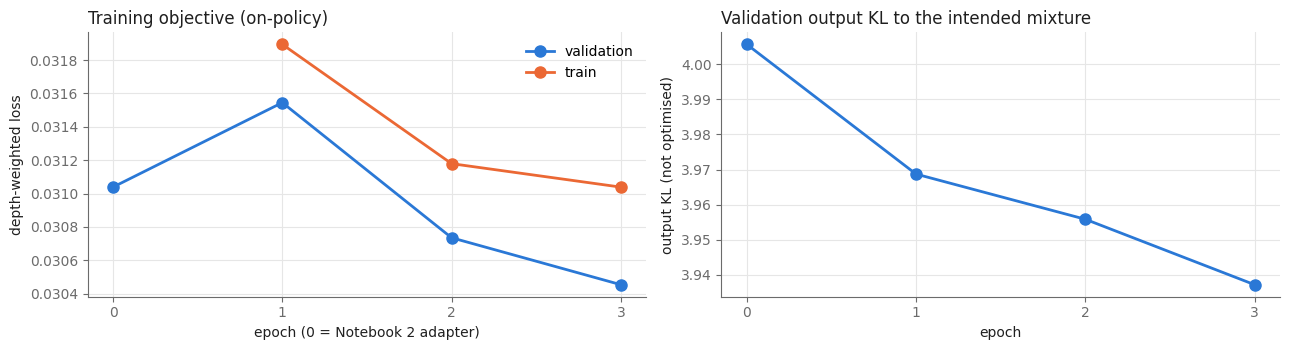

In [16]:
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1f1f1f", "#6b6b6b", "#e6e6e6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
                     "axes.titlelocation": "left", "axes.titlecolor": INK})
GRAY = "#8a8a8a"

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
ax = axes[0]
ax.plot(hist["epoch"], hist["val_loss"], color=BLUE, linewidth=2, marker="o", markersize=8, label="validation")
ax.plot(hist["epoch"][1:], hist["train_loss"][1:], color=ORANGE, linewidth=2, marker="o", markersize=8, label="train")
ax.set_xticks(hist["epoch"]); ax.set_xlabel("epoch (0 = Notebook 2 adapter)"); ax.set_ylabel("depth-weighted loss")
ax.set_title("Training objective (on-policy)"); ax.legend(frameon=False)
ax = axes[1]
ax.plot(hist["epoch"], hist["val_kl"], color=BLUE, linewidth=2, marker="o", markersize=8)
ax.set_xticks(hist["epoch"]); ax.set_xlabel("epoch"); ax.set_ylabel("output KL (not optimised)")
ax.set_title("Validation output KL to the intended mixture")
plt.tight_layout(); plt.show()

## 5.1 On-policy check

We decode held-out training questions with the calibrated adapter and compare them with the round-1 adapter on the same questions (their on-policy traces), under the same calibrated Cold Stop.

In [17]:
check_items = val_items[:CFG.n_policy_check]
check_set = [{"id": r["id"], "q": r["q"], "a": r["gold"]} for r in check_items]
check_cal = run_soft_thinking(check_set, "policy_check", cfg=CFG_CAL, adapter=cal_adapter)
check_table = pd.DataFrame([summarize(check_items, "round-1 adapter (Notebook 2)"),
                            summarize(check_cal, "calibrated adapter")]).set_index("system")
display(check_table.round(3))
base = check_table.loc["round-1 adapter (Notebook 2)"]
collapsed = (check_table.loc["calibrated adapter", "tail repetition"] > base["tail repetition"] + 0.2 or
             check_table.loc["calibrated adapter", "accuracy"] < base["accuracy"] - 0.2)
print("WARNING: collapse symptoms on held-out questions." if collapsed else "On-policy check passed.")

[policy_check]   16/16 | batch  322.5s | elapsed   5.4 min | running acc 0.938


,accuracy,avg think tokens,stop: </think>,stop: cold stop,stop: budget,no \boxed answer,mixed steps,tail repetition
system,,,,,,,,
round-1 adapter (Notebook 2),0.875,999.938,0.938,0.0,0.062,0.125,0.184,0.144
calibrated adapter,0.938,1058.625,0.938,0.0,0.062,0.125,0.194,0.176


On-policy check passed.


---
# Part 6: Evaluation on the test questions

The settings are identical to Notebook 3 (calibrated Cold Stop); the only change is the calibrated adapter.

In [18]:
cal_test = run_soft_thinking(test_set, "cal_adapter_test", cfg=CFG_CAL, adapter=cal_adapter)
diag_cal = diagnose_run(cal_test, "diag_cal_adapter", adapter=cal_adapter)
times["cal"] = json.load(open(f"{OUT_DIR}/cal_adapter_test_time.json"))["seconds"]

[cal_adapter_test]   16/250 | batch  311.2s | elapsed   5.2 min | running acc 0.812
[cal_adapter_test]   32/250 | batch  308.5s | elapsed  10.3 min | running acc 0.875
[cal_adapter_test]   48/250 | batch  308.6s | elapsed  15.5 min | running acc 0.875
[cal_adapter_test]   64/250 | batch  286.2s | elapsed  20.2 min | running acc 0.875
[cal_adapter_test]   80/250 | batch  280.5s | elapsed  24.9 min | running acc 0.887
[cal_adapter_test]   96/250 | batch  311.2s | elapsed  30.1 min | running acc 0.875
[cal_adapter_test]  112/250 | batch  312.6s | elapsed  35.3 min | running acc 0.884
[cal_adapter_test]  128/250 | batch  315.8s | elapsed  40.6 min | running acc 0.883
[cal_adapter_test]  144/250 | batch  290.7s | elapsed  45.4 min | running acc 0.889
[cal_adapter_test]  160/250 | batch  292.1s | elapsed  50.3 min | running acc 0.875
[cal_adapter_test]  176/250 | batch  315.8s | elapsed  55.6 min | running acc 0.881
[cal_adapter_test]  192/250 | batch  318.7s | elapsed  60.9 min | running ac

---
# Part 7: Comparison

## 7.1 Accuracy, efficiency and behaviour

In [19]:
NAMES = ("Soft Thinking (paper)", "+ calibrated Cold Stop", "+ calibrated Cold Stop + calibrated adapter (ours)")
SYSTEMS = ((NAMES[0], paper_test, diag_paper, "paper"), (NAMES[1], ccs_test, diag_ccs, "ccs"), (NAMES[2], cal_test, diag_cal, "cal"))
main_table = pd.DataFrame([summarize(r, n) for n, r, _, _ in SYSTEMS]).set_index("system")
main_table["test decoding (min)"] = [times[k] / 60 for *_, k in SYSTEMS]
main_table.round(3)

,accuracy,avg think tokens,stop: </think>,stop: cold stop,stop: budget,no \boxed answer,mixed steps,tail repetition,test decoding (min)
system,,,,,,,,,
Soft Thinking (paper),0.892,1342.180,0.720,0.000,0.280,0.036,0.214,0.174,82.565
+ calibrated Cold Stop,0.892,1317.368,0.704,0.028,0.268,0.040,0.214,0.173,79.320
+ calibrated Cold Stop + calibrated adapter (ours),0.904,1339.404,0.708,0.020,0.272,0.056,0.216,0.171,79.785


In [20]:
rows = []
for (an, ar, _, ak), (bn, br, _, bk), label in (((SYSTEMS[1]), (SYSTEMS[2]), "adapter effect (same Cold Stop)"),
                                                ((SYSTEMS[0]), (SYSTEMS[2]), "combined effect"),
                                                ((SYSTEMS[0]), (SYSTEMS[1]), "Cold Stop effect")):
    table, acc = paired_accuracy(ar, br, ak, bk)
    tk = paired_tokens(ar, br)
    print(f"--- {label}: rows = {an}, columns = {bn}")
    display(table)
    rows.append({"comparison": label, "accuracy a": np.mean([r["correct"] for r in ar]), "accuracy b": np.mean([r["correct"] for r in br]),
                 "only a correct": acc[f"{ak}-only correct"], "only b correct": acc[f"{bk}-only correct"], "McNemar p": acc["McNemar p"],
                 "tokens a": tk["mean tokens a"], "tokens b": tk["mean tokens b"], "token change": tk["relative change"],
                 "tokens Wilcoxon p": tk["Wilcoxon p"]})
acc_tests = pd.DataFrame(rows).set_index("comparison")
acc_tests.round(4)

--- adapter effect (same Cold Stop): rows = + calibrated Cold Stop, columns = + calibrated Cold Stop + calibrated adapter (ours)


,cal correct,cal wrong
ccs correct,214,9
ccs wrong,12,15


--- combined effect: rows = Soft Thinking (paper), columns = + calibrated Cold Stop + calibrated adapter (ours)


,cal correct,cal wrong
paper correct,214,9
paper wrong,12,15


--- Cold Stop effect: rows = Soft Thinking (paper), columns = + calibrated Cold Stop


,ccs correct,ccs wrong
paper correct,223,0
paper wrong,0,27


,accuracy a,accuracy b,only a correct,only b correct,McNemar p,tokens a,tokens b,token change,tokens Wilcoxon p
comparison,,,,,,,,,
adapter effect (same Cold Stop),0.892,0.904,9,12,0.6636,1317.368,1339.404,0.0167,0.1149
combined effect,0.892,0.904,9,12,0.6636,1342.180,1339.404,-0.0021,0.4895
Cold Stop effect,0.892,0.892,0,0,1.0000,1342.180,1317.368,-0.0185,0.0180


## 7.2 Superposition gap during real generation

Notebook 2's adapter, which ran under the paper's Cold Stop, is included as a reference row. It shows what on-policy, depth-weighted training adds to the gap reduction.

In [21]:
GAP_SYSTEMS = ((NAMES[0], diag_paper), (NAMES[1], diag_ccs), ("concept adapter (Notebook 2, reference)", nb2_diag), (NAMES[2], diag_cal))
gap_table = pd.DataFrame([diag_summary(d, n) for n, d in GAP_SYSTEMS]).set_index("system").T
gap_table.round(4)

system,Soft Thinking (paper),+ calibrated Cold Stop,"concept adapter (Notebook 2, reference)",+ calibrated Cold Stop + calibrated adapter (ours)
mixed steps probed,15909.0000,15909.0000,15943.0000,15948.0000
norm ratio (mean),0.8515,0.8513,0.8466,0.8473
input shift (mean),0.0002,0.0002,0.1275,0.1493
"gap, all layers (mean)",0.1425,0.1428,0.1328,0.1380
"gap, final layer (mean)",0.2055,0.2060,0.1978,0.1975
"dist to top-1, final layer (mean)",0.0786,0.0788,0.0801,0.0923
closer to top-1 than to superposition,0.9008,0.9013,0.8952,0.8714
output KL (mean),4.1950,4.2073,4.0140,3.9946
output KL (median),2.7976,2.8115,2.6600,2.7229
argmax agrees with mixture,0.9272,0.9277,0.9307,0.9258


In [22]:
def gap_test(da, db, metric):
    pa, pb = da.groupby("id")[metric].mean(), db.groupby("id")[metric].mean()
    ids = pa.index.intersection(pb.index)
    x, y = pa.loc[ids].values, pb.loc[ids].values
    return {"metric": metric, "questions": len(ids), "a": x.mean(), "b": y.mean(), "relative change": (y.mean() - x.mean()) / x.mean(),
            "b lower on": f"{(y < x).mean():.0%}", "Wilcoxon p": paired_wilcoxon(x, y)}

gap_tests = pd.DataFrame([{"comparison": lab, **gap_test(da, db, m)}
                          for lab, da, db in (("adapter effect (vs calibrated Cold Stop)", diag_ccs, diag_cal),
                                              ("combined (vs paper)", diag_paper, diag_cal),
                                              ("vs Notebook 2 adapter", nb2_diag, diag_cal))
                          for m in ("gap_layers", "gap_hidden", "kl_output")])
gap_tests.round(4)

,comparison,metric,questions,a,b,relative change,b lower on,Wilcoxon p
0,adapter effect (vs calibrated Cold Stop),gap_layers,250,0.1428,0.1380,-0.0341,59%,0.0000
1,adapter effect (vs calibrated Cold Stop),gap_hidden,250,0.2059,0.1975,-0.0410,58%,0.0001
2,adapter effect (vs calibrated Cold Stop),kl_output,250,4.2081,3.9962,-0.0504,61%,0.0001
3,combined (vs paper),gap_layers,250,0.1425,0.1380,-0.0317,58%,0.0001
4,combined (vs paper),gap_hidden,250,0.2054,0.1975,-0.0387,58%,0.0004
5,combined (vs paper),kl_output,250,4.1959,3.9962,-0.0476,61%,0.0002
6,vs Notebook 2 adapter,gap_layers,250,0.1328,0.1380,0.0388,38%,0.0000
7,vs Notebook 2 adapter,gap_hidden,250,0.1977,0.1975,-0.0014,53%,0.6512
8,vs Notebook 2 adapter,kl_output,250,4.0136,3.9962,-0.0043,51%,0.5823


## 7.3 Plots

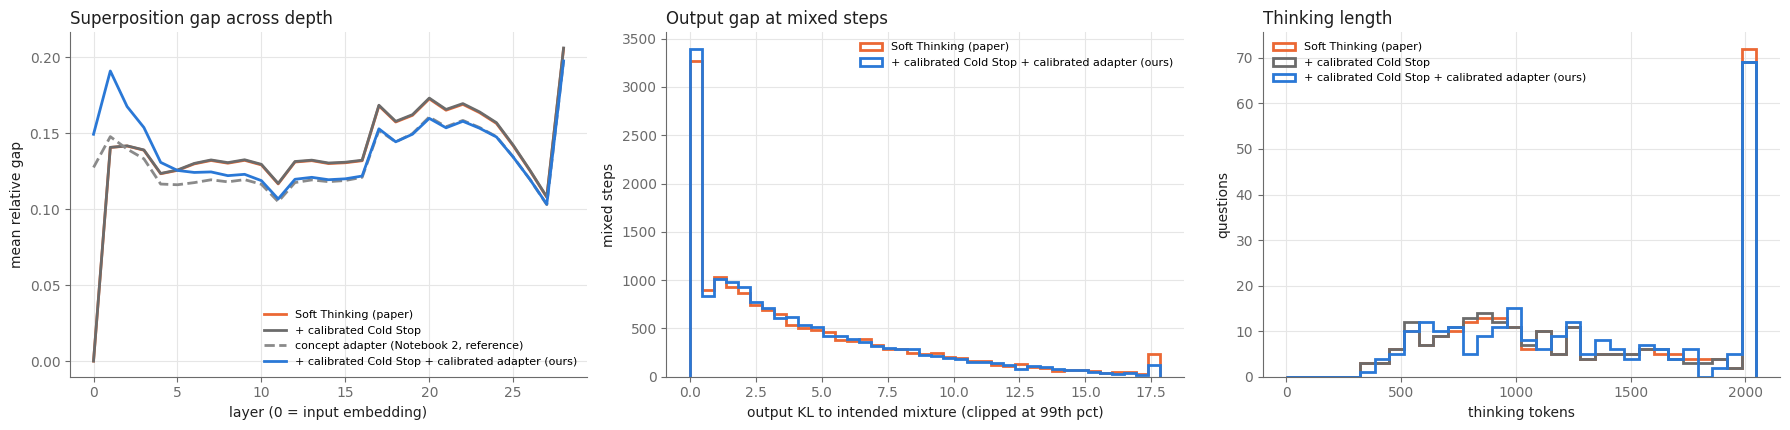

In [23]:
layer_cols = [c for c in diag_paper.columns if c.startswith("gap_L")]
COL = {NAMES[0]: ORANGE, NAMES[1]: MUTED, "concept adapter (Notebook 2, reference)": GRAY, NAMES[2]: BLUE}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))

ax = axes[0]
for name, d in GAP_SYSTEMS:
    ax.plot(range(len(layer_cols)), d[layer_cols].mean().values, color=COL[name], linewidth=2,
            linestyle="--" if "reference" in name else "-", label=name)
ax.set_xlabel("layer (0 = input embedding)"); ax.set_ylabel("mean relative gap")
ax.set_title("Superposition gap across depth"); ax.legend(frameon=False, fontsize=8)

ax = axes[1]
hi = float(np.quantile(np.concatenate([d["kl_output"].values for _, d in GAP_SYSTEMS]), 0.99))
bins = np.linspace(0, hi, 40)
for name, d in (GAP_SYSTEMS[0], GAP_SYSTEMS[3]):
    ax.hist(d["kl_output"].clip(upper=hi), bins=bins, histtype="step", linewidth=2, color=COL[name], label=name)
ax.set_xlabel("output KL to intended mixture (clipped at 99th pct)"); ax.set_ylabel("mixed steps")
ax.set_title("Output gap at mixed steps"); ax.legend(frameon=False, fontsize=8)

ax = axes[2]
bins = np.linspace(0, CFG.max_think_tokens, 33)
for name, res, _, _ in SYSTEMS:
    ax.hist([r["think_tokens"] for r in res], bins=bins, histtype="step", linewidth=2, color=COL[name], label=name)
ax.set_xlabel("thinking tokens"); ax.set_ylabel("questions"); ax.set_title("Thinking length"); ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## 7.4 Cost

In [24]:
tt = json.load(open(f"{OUT_DIR}/onpolicy_traces_time.json"))["seconds"] if os.path.exists(f"{OUT_DIR}/onpolicy_traces_time.json") else float("nan")
cost = pd.DataFrame([
    {"item": "trainable parameters", NAMES[0]: 0, NAMES[1]: 0, NAMES[2]: N_ADAPTER_PARAMS},
    {"item": "labels used", NAMES[0]: "none", NAMES[1]: "train answers, only to evaluate Cold Stop settings", NAMES[2]: "same as Cold Stop; none for the adapter"},
    {"item": "extra training compute (min)", NAMES[0]: 0, NAMES[1]: "~1 (CPU calibration)",
     NAMES[2]: f"Notebook 2 adapter + {tt/60:.0f} traces + {train_seconds/60:.0f} training"},
    {"item": "test decoding (min)", **{n: round(times[k] / 60, 1) for n, _, _, k in SYSTEMS}},
]).set_index("item")
cost

,Soft Thinking (paper),+ calibrated Cold Stop,+ calibrated Cold Stop + calibrated adapter (ours)
item,,,
trainable parameters,0,0,264256
labels used,none,"train answers, only to evaluate Cold Stop sett...",same as Cold Stop; none for the adapter
extra training compute (min),0,~1 (CPU calibration),Notebook 2 adapter + 125 traces + 17 training
test decoding (min),82.6,79.3,79.8


---
# Part 8: Conclusion

In [25]:
m, at = main_table, acc_tests
gl = gap_tests.set_index(["comparison", "metric"])
print(f"""ACCURACY ({len(test_set)} questions)
  paper {m.loc[NAMES[0], 'accuracy']:.1%} | + calibrated Cold Stop {m.loc[NAMES[1], 'accuracy']:.1%} | + calibrated adapter {m.loc[NAMES[2], 'accuracy']:.1%}
  adapter effect: McNemar p = {at.loc['adapter effect (same Cold Stop)', 'McNemar p']:.3f} | combined vs paper: McNemar p = {at.loc['combined effect', 'McNemar p']:.3f}

EFFICIENCY
  avg thinking tokens {m.loc[NAMES[0], 'avg think tokens']:.0f} -> {m.loc[NAMES[1], 'avg think tokens']:.0f} -> {m.loc[NAMES[2], 'avg think tokens']:.0f}
  combined vs paper: {at.loc['combined effect', 'token change']:+.1%}, Wilcoxon p = {at.loc['combined effect', 'tokens Wilcoxon p']:.2g}
  test decoding {m.loc[NAMES[0], 'test decoding (min)']:.0f} -> {m.loc[NAMES[1], 'test decoding (min)']:.0f} -> {m.loc[NAMES[2], 'test decoding (min)']:.0f} min

SUPERPOSITION GAP (all layers / final layer / output KL)
  adapter effect: {gl.loc[('adapter effect (vs calibrated Cold Stop)', 'gap_layers'), 'relative change']:+.1%} (p = {gl.loc[('adapter effect (vs calibrated Cold Stop)', 'gap_layers'), 'Wilcoxon p']:.2g}) / {gl.loc[('adapter effect (vs calibrated Cold Stop)', 'gap_hidden'), 'relative change']:+.1%} (p = {gl.loc[('adapter effect (vs calibrated Cold Stop)', 'gap_hidden'), 'Wilcoxon p']:.2g}) / {gl.loc[('adapter effect (vs calibrated Cold Stop)', 'kl_output'), 'relative change']:+.1%} (p = {gl.loc[('adapter effect (vs calibrated Cold Stop)', 'kl_output'), 'Wilcoxon p']:.2g})
  vs Notebook 2 adapter: {gl.loc[('vs Notebook 2 adapter', 'gap_layers'), 'relative change']:+.1%} / {gl.loc[('vs Notebook 2 adapter', 'gap_hidden'), 'relative change']:+.1%} / {gl.loc[('vs Notebook 2 adapter', 'kl_output'), 'relative change']:+.1%}""")

main_table.to_csv(f"{OUT_DIR}/final_results.csv")
acc_tests.to_csv(f"{OUT_DIR}/final_accuracy_token_tests.csv")
gap_table.to_csv(f"{OUT_DIR}/final_gap.csv")
gap_tests.to_csv(f"{OUT_DIR}/final_gap_tests.csv", index=False)
hist.to_csv(f"{OUT_DIR}/calibrated_adapter_history.csv", index=False)
with open(f"{OUT_DIR}/config.json", "w") as f:
    json.dump({"run_mode": RUN_MODE, "model": MODEL_NAME, "inputs": [NB1_DIR, NB2_DIR, NB3_DIR],
               "cold_stop": CAL, **asdict(CFG)}, f, indent=2)
print("\nsaved:", sorted(os.listdir(OUT_DIR)))

ACCURACY (250 questions)
  paper 89.2% | + calibrated Cold Stop 89.2% | + calibrated adapter 90.4%
  adapter effect: McNemar p = 0.664 | combined vs paper: McNemar p = 0.664

EFFICIENCY
  avg thinking tokens 1342 -> 1317 -> 1339
  combined vs paper: -0.2%, Wilcoxon p = 0.49
  test decoding 83 -> 79 -> 80 min

SUPERPOSITION GAP (all layers / final layer / output KL)
  adapter effect: -3.4% (p = 2.8e-05) / -4.1% (p = 0.00014) / -5.0% (p = 7.6e-05)
  vs Notebook 2 adapter: +3.9% / -0.1% / -0.4%

saved: ['cal_adapter_test.pkl', 'cal_adapter_test_time.json', 'calibrated_adapter.pt', 'calibrated_adapter_history.csv', 'config.json', 'diag_cal_adapter.pkl', 'final_accuracy_token_tests.csv', 'final_gap.csv', 'final_gap_tests.csv', 'final_results.csv', 'onpolicy_traces.pkl', 'onpolicy_traces_time.json', 'policy_check.pkl', 'policy_check_time.json']


**Interpretation.**

* **Adapter effect, same stopping rule.** This compares the calibrated adapter with Notebook 3. A significant gap reduction that persists at the **final layer**, which is what depth-weighting targets, is the adapter's contribution. Accuracy is expected to stay statistically unchanged.
* **Combined effect.** This compares the calibrated adapter + calibrated Cold Stop with Notebook 1. Efficiency gains come mainly from the calibrated Cold Stop, gap reductions from the adapter. Together they answer the two small-scale limitations of Soft Thinking identified in this project.
* **Versus Notebook 2's adapter.** This shows whether on-policy, depth-weighted training adds to the gap reduction, particularly at the late layers.

**Limitations.**

* One model, one dataset, one run per system, and fixed hyperparameters.
* The adapter is trained with one on-policy round.
* GPU training is not bit-exact, so the adapter's accuracy can vary by about a point between runs.